# Solve a two-reaction, six-product adiabatic equilibrium model for a methane-air stream.

Run in a Python environment with OneSimulation 0.2.0, NumPy, SciPy and Matplotlib. Change the input data and rerun to compare with the saved reference output.

1 bar: T = 2286.01 K, extents = 0.11117, 0.03649 mol
product moles [0.88883 0.11117 1.96351 0.03649 0.07383 7.52   ]
5 bar: T = 2319.34 K, extents = 0.07711, 0.02403 mol
product moles [0.92289 0.07711 1.97597 0.02403 0.05057 7.52   ]


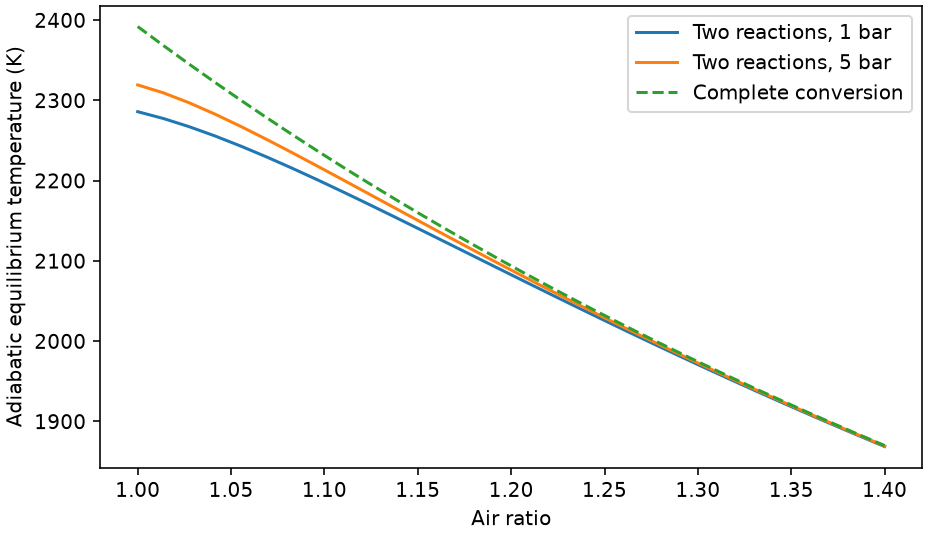

In [1]:
"""Solve a two-reaction, six-product adiabatic equilibrium model for a methane-air stream."""
import numpy as np
import matplotlib.pyplot as plt
from onesim.numerics.nonlinear import LeastSquares

# Species order: CO2, CO, H2O(g), H2, O2, N2. Reference state 298.15 K and 1 bar.
reference = 298.15
gas_constant = 8.314462618  # J/(mol K)
hf = 1000*np.array([-393.52, -110.53, -241.83, 0.0, 0.0, 0.0])  # J/mol
entropy_ref = np.array([213.79,197.66,188.84,130.68,205.15,191.61])  # J/(mol K)
cp = np.array([51.,33.,42.,31.,35.,33.])  # constant teaching-model mean heat capacities
nu = np.array([[-1.,1.,0.,0.,0.5,0.], [0.,0.,-1.,1.,0.5,0.]])
element_counts = np.array([[1,1,0,0,0,0], [0,0,2,2,0,0],
                           [2,1,1,0,2,0], [0,0,0,0,0,2]])
inlet_enthalpy = -74870.0  # J per mole methane, with all reactants at 298.15 K

def equilibrate(air_ratio, pressure_bar):
    complete = np.array([1.,0.,2.,0.,2*(air_ratio-1),7.52*air_ratio])
    def residual(state):
        extents, temperature = state[:2],state[2]
        moles = complete + extents @ nu
        enthalpies = hf + cp*(temperature-reference)
        entropies = entropy_ref + cp*np.log(temperature/reference)
        log_k = -(nu @ (enthalpies-temperature*entropies))/(gas_constant*temperature)
        log_q = nu @ np.log(pressure_bar*moles/moles.sum())
        return np.r_[log_q-log_k, (moles @ enthalpies-inlet_enthalpy)/1e5]
    optimum = LeastSquares(options={"gtol":1e-13,"xtol":1e-13,"ftol":1e-13}).solve(
        residual,[0.06,0.04,2200.0], bounds=([1e-12,1e-12,500.],[1-1e-12,2-1e-12,3500.]))
    assert np.max(np.abs(optimum.fun)) < 1e-8
    moles = complete + optimum.x[:2] @ nu
    assert np.allclose(element_counts @ moles, element_counts @ complete)
    return optimum.x, moles

for pressure in [1.,5.]:
    result, moles = equilibrate(1.0, pressure)
    print(f"{pressure:.0f} bar: T = {result[2]:.2f} K, extents = {result[0]:.5f}, {result[1]:.5f} mol")
    print("product moles",np.round(moles,5))
ratios = np.linspace(1.0, 1.4, 30)
fig,ax = plt.subplots(figsize=(6.4,3.7),layout="constrained")
for pressure in [1.,5.]:
    temperature = [equilibrate(r,pressure)[0][2] for r in ratios]
    ax.plot(ratios,temperature,label=f"Two reactions, {pressure:g} bar")
complete_temp = reference + 802310/(51+2*42+2*(ratios-1)*35+7.52*ratios*33)
ax.plot(ratios,complete_temp,"--",label="Complete conversion")
ax.set(xlabel="Air ratio",ylabel="Adiabatic equilibrium temperature (K)")
ax.legend()
plt.show()
